# SAM2 Timing Analysis

This notebook helps analyze the execution timing logs generated by SAM2.
It assumes logs are stored in JSON Lines format with fields like `name`, `duration_ms`, `video_path`, etc.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import glob
import os

# Set plot style to match academic format
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 14,
    'axes.titlesize': 26,
    'axes.labelsize': 22,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'figure.titlesize': 30,
    'figure.figsize': (12, 8)
})

## Load Data
Define the path to your log files. You can use wildcards (e.g., `logs/timing_measures/*.log`).

In [2]:
LOG_PATTERN = "evaluations/*.log"  # Update this path to match your log location

def load_logs(pattern):
    data = []
    files = glob.glob(pattern)
    print(f"Found {len(files)} log files.")
    
    for file in files:
        with open(file, 'r') as f:
            for line in f:
                try:
                    entry = json.loads(line)
                    # Extract video name from path for cleaner grouping
                    if "video_path" in entry and entry["video_path"]:
                         entry["video_name"] = os.path.basename(entry["video_path"])
                    else:
                         entry["video_name"] = "unknown"
                         # add name of the config file
                    entry["config_name"] = os.path.basename(file).split('.')[0]
                    data.append(entry)
                except json.JSONDecodeError:
                    continue
    
    df = pd.DataFrame(data)
    return df

df = load_logs(LOG_PATTERN)
if not df.empty:
    print(f"Loaded {len(df)} entries.")
    display(df.head())

else:
    print("No data loaded. Check LOG_PATTERN.")

Found 15 log files.


Loaded 72164 entries.


,name,duration_ms,timestamp,video_path,video_name,config_name,frame_idx
0,Image Encoder,167.612411,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,NaN
1,Init State,1527.354370,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,NaN
2,Image Encoder,16.560127,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,NaN
3,SAM Decoder,103.153664,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,5.0
4,Track Step (Total),163.239044,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,5.0


## 1. Summary Statistics by Component
Average execution time for each tracked component across all videos.

,mean,std,min,max,count
name,,,,,
Init State,1163.424539,561.998430,245.297150,2286.849121,247
Track Step (Total),23.958653,9.219564,7.902208,420.601868,14334
Image Encoder,15.954991,7.572158,15.063904,573.385742,15320
Memory Attention,13.404656,5.013138,6.619136,260.495361,13595
SAM Decoder,6.705670,4.905375,5.637120,281.400269,14334
Memory Encoder,1.882289,0.928260,1.356800,63.403263,14334


/tmp/ipykernel_1609007/838919207.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df, x="duration_ms", y="name", errorbar='sd', palette="viridis")


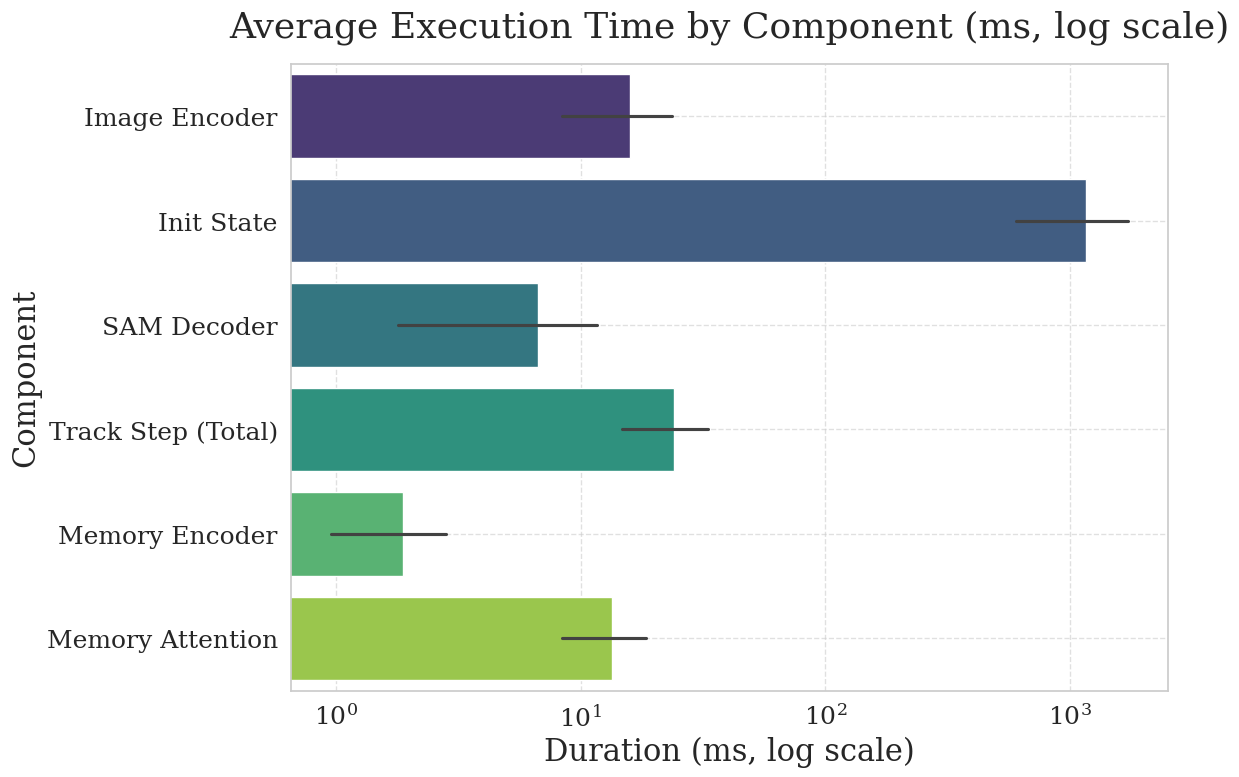

In [3]:
if not df.empty:
    summary = df.groupby("name")["duration_ms"].agg(['mean', 'std', 'min', 'max', 'count']).sort_values("mean", ascending=False)
    display(summary)
    
    # Bar plot of average durations (log scale)
    plt.figure()
    ax = sns.barplot(data=df, x="duration_ms", y="name", errorbar='sd', palette="viridis")
    ax.set_xscale("log")
    ax.grid(True, which='major', linestyle='--', alpha=0.6)
    plt.title("Average Execution Time by Component (ms, log scale)", pad=20)
    plt.xlabel("Duration (ms, log scale)")
    plt.ylabel("Component")
    plt.tight_layout()
    plt.show()

In [4]:
df

,name,duration_ms,timestamp,video_path,video_name,config_name,frame_idx
0,Image Encoder,167.612411,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,NaN
1,Init State,1527.354370,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,NaN
2,Image Encoder,16.560127,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,NaN
3,SAM Decoder,103.153664,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,5.0
4,Track Step (Total),163.239044,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_8osr279l,gate_5,5.0
...,...,...,...,...,...,...,...
72159,Image Encoder,15.460352,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_2oz302co,gate_3,NaN
72160,Memory Attention,15.386528,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_2oz302co,gate_3,29.0
72161,SAM Decoder,6.510592,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_2oz302co,gate_3,29.0
72162,Memory Encoder,1.910784,1.765933e+09,/home/sam2group/Sam2/ML-P2-Sam2/tmp/single_for...,single_forward_2oz302co,gate_3,29.0


## 2. Tracking Time per Frame over Video Duration
Analyze if tracking speed degrades over time (as `frame_idx` increases).

/tmp/ipykernel_1609007/143879480.py:39: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


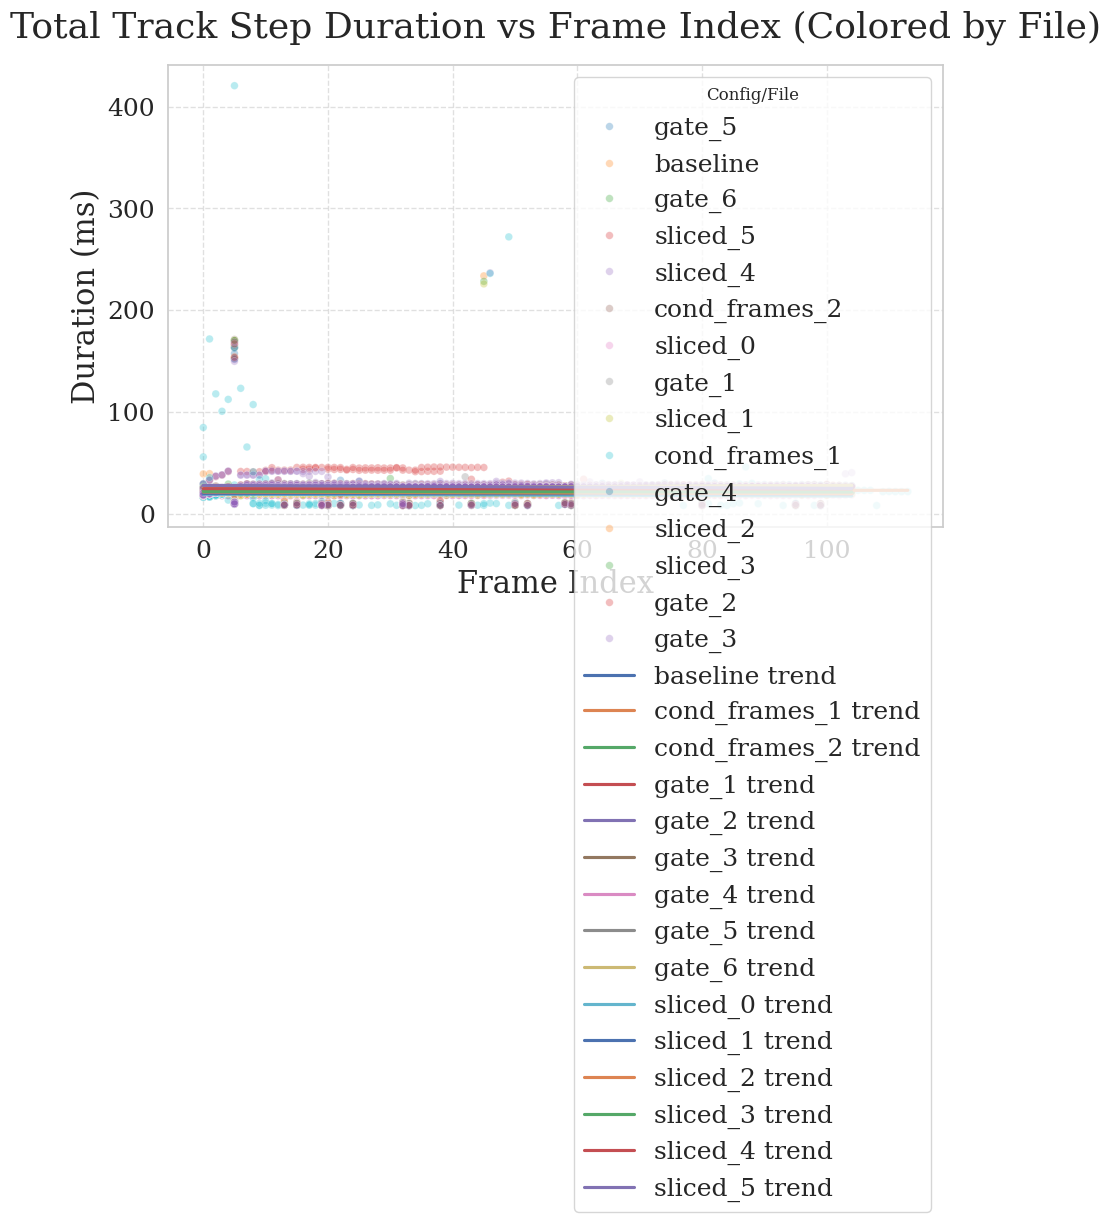

In [5]:
if not df.empty and "frame_idx" in df.columns:
    track_steps = df[df["name"] == "Track Step (Total)"].copy()
    
    if not track_steps.empty:
        plt.figure(figsize=(10,6))
        # Color by config_name (file)
        if "config_name" in track_steps.columns:
            ax = sns.scatterplot(
                data=track_steps, 
                x="frame_idx", 
                y="duration_ms", 
                hue="config_name", 
                alpha=0.3, 
                s=30,
                palette="tab10"
            )
            # Optionally add per-file regression lines
            for config, subdf in track_steps.groupby("config_name"):
                sns.regplot(
                    data=subdf, x="frame_idx", y="duration_ms",
                    scatter=False, label=f"{config} trend"
                )
            plt.legend(title="Config/File")
        else:
            # fallback: just a single-color scatter
            ax = sns.scatterplot(
                data=track_steps, 
                x="frame_idx", 
                y="duration_ms", 
                alpha=0.3, 
                s=30
            )
            sns.regplot(data=track_steps, x="frame_idx", y="duration_ms",
                        scatter=False, color="red")
        plt.grid(True, which='major', linestyle='--', alpha=0.6)
        plt.title("Total Track Step Duration vs Frame Index (Colored by File)", pad=20)
        plt.xlabel("Frame Index")
        plt.ylabel("Duration (ms)")
        plt.tight_layout()
        plt.show()
    else:
        print("No 'Track Step (Total)' entries found.")
else:
    print("Dataframe empty or missing 'frame_idx'.")

## 3. Comparison by Video Case
Compare the average tracking performance across different video volumes.

/tmp/ipykernel_1609007/2360916891.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


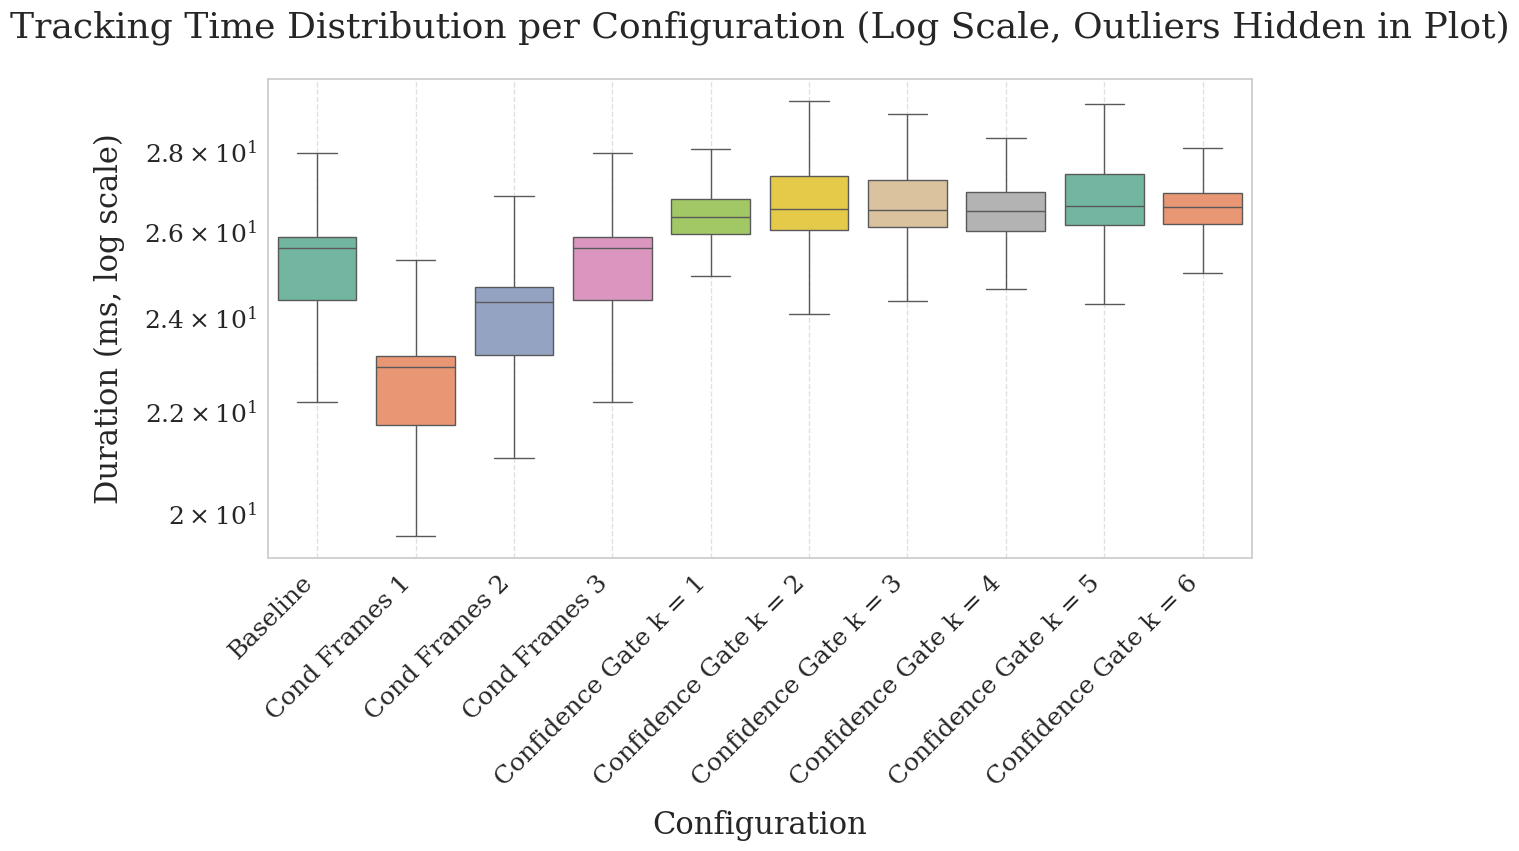

,mean,count
config_name,,
baseline,24.860818,1196
cond_frames_1,22.560248,2842
cond_frames_2,23.645427,1196
cond_frames_3,24.860818,1196
gate_1,25.594918,1196
gate_2,25.812209,1196
gate_3,25.888849,1196
gate_4,25.741111,728
gate_5,25.844900,598


In [ ]:
if not df.empty:
    track_steps_plot = df[df["name"] == "Track Step (Total)"]

    names_map = {
        "baseline": "Baseline",
        "cond_frames_1": "Cond Frames 1",
        "cond_frames_2": "Cond Frames 2",
        "cond_frames_3": "Cond Frames 3",
        "gate_1": "Confidence Gate k = 1",
        "gate_2": "Confidence Gate k = 2",
        "gate_3": "Confidence Gate k = 3",
        "gate_4": "Confidence Gate k = 4",
        "gate_5": "Confidence Gate k = 5",
        "gate_6": "Confidence Gate k = 6",
        "sliced_0": "Number of Frames = 1",
        "sliced_1": "Number of Frames = 2",
        "sliced_2": "Number of Frames = 3",
        "sliced_3": "Number of Frames = 4",
        "sliced_4": "Number of Frames = 5",
        "sliced_5": "Number of Frames = 6",
    }
    order = [
        "Baseline",
        "Cond Frames 1",
        "Cond Frames 2",
        "Cond Frames 3",
        "Confidence Gate k = 1",
        "Confidence Gate k = 2",
        "Confidence Gate k = 3",
        "Confidence Gate k = 4",
        "Confidence Gate k = 5",
        "Confidence Gate k = 6",
        "Number of Frames = 1",
        "Number of Frames = 2",
        "Number of Frames = 3",
        "Number of Frames = 4",
        "Number of Frames = 5",
        "Number of Frames = 6",
    ]
    if not track_steps.empty:
        def iqr_bounds(series):
            q1 = series.quantile(0.25)
            q3 = series.quantile(0.75)
            iqr = q3 - q1
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr
            return lower, upper

        if "config_name" in track_steps.columns:
            # Ensure all configs in names_map/order appear, even if missing in data, by faking empty rows if needed.

            configs_in_data = set(track_steps["config_name"].unique())

            # Always start from original data for repeatability
            track_steps_plot = track_steps.copy()

            # Always duplicate baseline as cond_frames_3 and gate_6 (for completeness)
            baseline_rows = track_steps[track_steps["config_name"] == "baseline"]

            # Duplicate as "cond_frames_3"
            new_rows_cf3 = baseline_rows.copy()
            new_rows_cf3["config_name"] = "cond_frames_3"
            # Duplicate as "gate_6"
            # Append these to main dataframe for plotting
            track_steps_plot = pd.concat(
                [track_steps_plot, new_rows_cf3], ignore_index=True
            )

            # Now: to guarantee all configs show up, if any config in order/names_map is missing, add a dummy row for that config (NaN duration)
            present_configs = set(track_steps_plot["config_name"].unique())
            for canonical_config in names_map.keys():
                if canonical_config not in present_configs:
                    # Add a (hidden) dummy row so its box will appear as empty
                    dummy_row = {
                        "config_name": canonical_config,
                        "duration_ms": np.nan,
                        "config_label": names_map[canonical_config],
                    }
                    # Add missing columns to dummy_row if needed
                    for col in set(track_steps_plot.columns) - set(dummy_row.keys()):
                        dummy_row[col] = np.nan
                    track_steps_plot = pd.concat([track_steps_plot, pd.DataFrame([dummy_row])], ignore_index=True)

            track_steps_plot = track_steps_plot[track_steps_plot["duration_ms"] > 0]
            track_steps_plot["config_label"] = track_steps_plot["config_name"].map(names_map)

            # Restrict only to those listed in order
            track_steps_plot = track_steps_plot[track_steps_plot["config_label"].isin(order)]

            bounds = track_steps.groupby("config_name")["duration_ms"].apply(iqr_bounds)
            flierprops = dict(marker='x', markersize=4, linestyle='none', markerfacecolor='gray', markeredgecolor='gray', alpha=0.3)
            plt.figure(figsize=(12, 9))
            ax = sns.boxplot(
                data=track_steps_plot,
                x="config_label",
                y="duration_ms",
                palette="Set2",
                showfliers=False,
                order=order
            )
            ax.set_yscale('log')
            plt.grid(True, which='major', linestyle='--', alpha=0.6)
            plt.xticks(rotation=45, ha='right')
            plt.title("Tracking Time Distribution per Configuration (Log Scale, Outliers Hidden in Plot)", pad=30)
            plt.xlabel("Configuration", labelpad=14)
            plt.ylabel("Duration (ms, log scale)", labelpad=14)
            plt.tight_layout(rect=[0, 0, 1, 0.97])
            plt.show()

            # Show table for all configs, including ones that may have no data (NaN for stats)
            config_stats = (
                track_steps_plot
                .groupby("config_name")["duration_ms"]
                .agg(['mean', 'count'])
                .reindex(list(names_map.keys()))  # ensures all, in canonical order
            )
            display(config_stats)
        else:
            bounds = track_steps.groupby("video_name")["duration_ms"].apply(iqr_bounds)
            plt.figure(figsize=(12, 9))  # make plot higher
            track_steps_plot = track_steps[track_steps["duration_ms"] > 0]
            ax = sns.boxplot(
                data=track_steps_plot,
                x="video_name",
                y="duration_ms",
                palette="Set2",
                showfliers=False
            )
            ax.set_yscale('log')
            plt.grid(True, which='major', linestyle='--', alpha=0.6)
            plt.xticks(rotation=45, ha='right')
            plt.title("Tracking Time Distribution per Video Case (Log Scale, Outliers Hidden in Plot)", pad=30)
            plt.xlabel("Video Case", labelpad=14)
            plt.ylabel("Duration (ms, log scale)", labelpad=14)
            plt.tight_layout(rect=[0, 0, 1, 0.97])
            plt.show()

            # Table view
            video_stats = track_steps.groupby("video_name")["duration_ms"].agg(['mean', 'count']).sort_values("mean", ascending=False)
            display(video_stats)

## 4. Sub-component Breakdown
Visualize how much time is spent in Memory Attention vs SAM Decoder vs Memory Encoder.

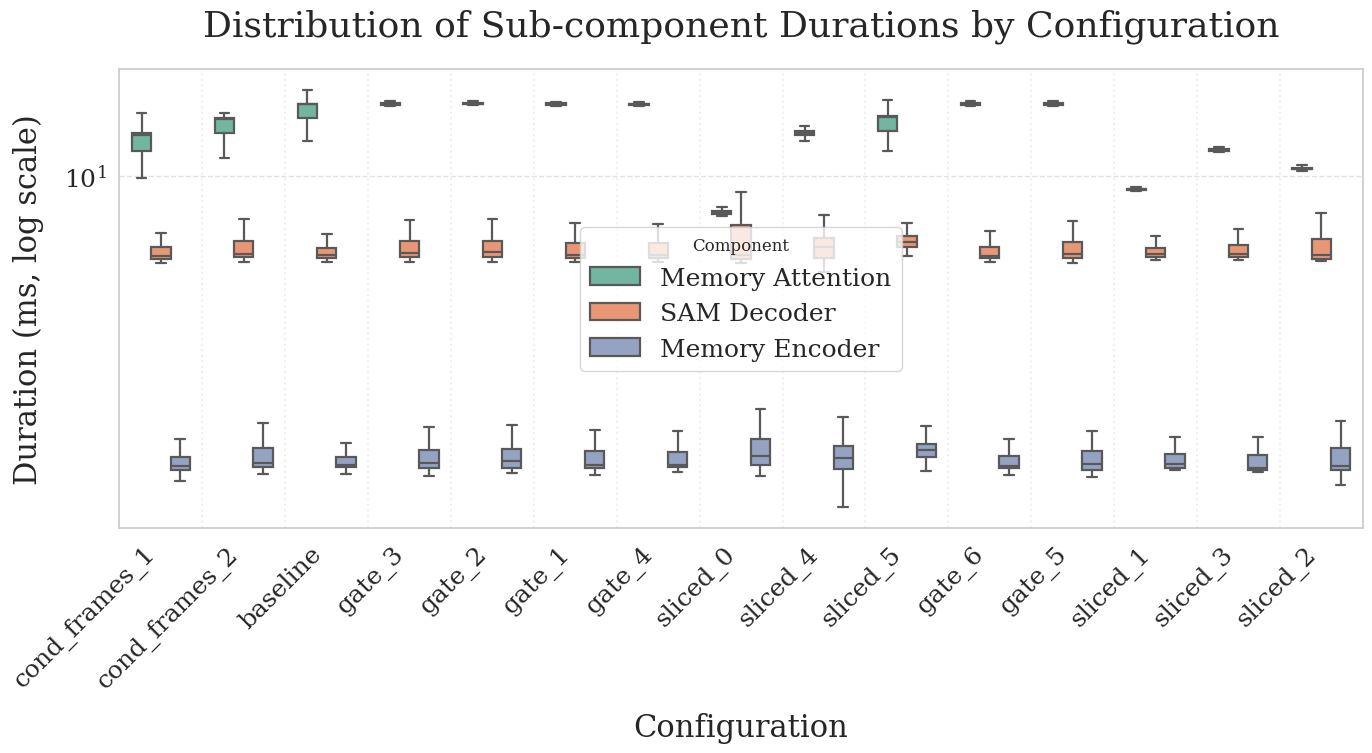

In [7]:
if not df.empty:
    # Components to plot
    components = ["Memory Attention", "SAM Decoder", "Memory Encoder"]
    # Get config order from previous cell logic for consistency
    config_order = (
        df["config_name"].value_counts().index.tolist() if "config_name" in df.columns else None
    )
    sub_df = df[df["name"].isin(components)].copy()
    sub_df = sub_df.dropna(subset=["config_name"])

    if config_order is not None:
        sub_df = sub_df[sub_df["config_name"].isin(config_order)]

    if not sub_df.empty:
        plt.figure(figsize=(14, 8))
        ax = sns.boxplot(
            data=sub_df,
            x="config_name",
            y="duration_ms",
            hue="name",
            hue_order=components,
            order=config_order,
            palette="Set2",
            showfliers=False,
            width=0.7,         # make boxes narrower for clarity
            dodge=True,        # keep grouping by hue separate
            linewidth=1.6      # bolder box lines
        )
        ax.set_yscale('log')

        # Visually separate each config group with a vertical grid/shaded region
        for i in range(len(config_order)):
            ax.axvline(i - 0.5, color='grey', lw=1.5, ls=':', alpha=0.12, zorder=0)
        ax.axvline(len(config_order) - 0.5, color='grey', lw=1.4, ls=':', alpha=0.15, zorder=0)

        # Optionally, increase space between groups by adjusting xtick locations
        plt.xticks(rotation=45, ha='right')
        plt.grid(True, which='major', axis='y', linestyle='--', alpha=0.58)
        plt.title("Distribution of Sub-component Durations by Configuration", pad=24)
        plt.xlabel("Configuration", labelpad=14)
        plt.ylabel("Duration (ms, log scale)", labelpad=14)
        plt.legend(title="Component")
        plt.tight_layout(rect=[0, 0, 1, 0.97])
        plt.show()
    else:
        print("No sub-component data found.")